In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'merge')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'development', 'misc')

In [3]:
g = (pd.read_csv(os.path.join(pth_feat, 'union.csv'))
     .mmusculus.drop_duplicates().tolist()) + \
     ['Snai1', 'Twist2', 'Foxc1', 'Zeb1', 'Zeb2', 'Prrx2']

In [4]:
labels_dict = {
    'Epiblast'                   : 'Epi',
    'Posterior Epiblast'         : 'pEpi',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Nascent Endothelium'        : 'NE',
    'Neuromesodermal Progenitor' : 'NMP',
    'Presomitic Mesoderm'        : 'PSM',
    'Somite'                     : 'Somite',
    'Premigratory Neural Crest'  : 'pmNC',
    'Migratory Neural Crest'     : 'mNC',
    'Neuroglial Progenitors'     : 'NGP',
    'Cranial Mesenchyme'         : 'CM'}
celltypes = list(labels_dict.keys())

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectories.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes), g].copy()
adata.X = np.asarray(adata.X.toarray() - adata.X.mean(axis = 1))
adata

AnnData object with n_obs × n_vars = 14344 × 243
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

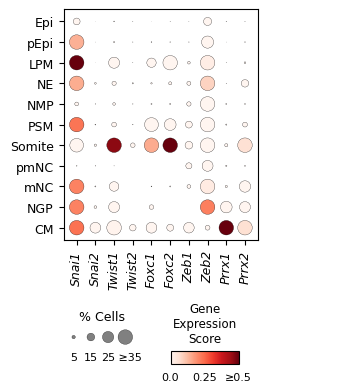

In [6]:
g_plt = ['Snai1', 'Snai2', 'Twist1', 'Twist2', 'Foxc1',
         'Foxc2', 'Zeb1', 'Zeb2', 'Prrx1', 'Prrx2']

# expression dotplot
fs1, fs2 = 9, 8
dp = sc.pl.dotplot(adata, g_plt, 'celltype',
                   categories_order = celltypes,
                   dot_max = .35,
                   vmin = 0, vmax = .5,
                   figsize = (3.65, 3),
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 110,
         x_padding = .7,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs1, pad = -17)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = .5)
ax_size.set_xticklabels(['5', '15', '25', '   ≥35'])
cax.set_title('Gene\nExpression\nScore', size = fs1 - .5, pad = 6)
cax.set_xticks([0, .25, .5], ['0.0', '0.25', '≥0.5'])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 6)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_main.x0 + .025 * pos_main.width,
                      pos_main.y0 - .48 * pos_main.height,
                      .35 * pos_main.width,
                      pos_size.height])

cax.set_position([pos_main.x0 + .55 * pos_main.width,
                  pos_main.y0 - .535 * pos_main.height,
                  .35 * pos_main.width,
                  .8 * pos_color.height])

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        fontsize = fs1,
                        fontstyle = 'italic')

ax_main.set_yticklabels([labels_dict[lbl.get_text()] for
                         lbl in ax_main.get_yticklabels()],
                        fontsize = fs1)

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')